# Sleep Health & Daily Performance
## Association and inferential statistics


In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import os
import shutil
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.core.magic import register_cell_magic
from IPython.display import Image, display
from scipy import stats

population = pd.read_csv("sleep_health_population.csv")
sample = pd.read_csv("sleep_health_sample_500.csv")
N = len(population)
risk_levels = ["Healthy", "Mild", "Moderate", "Severe"]
risk_map = {level: rank for rank, level in enumerate(risk_levels, start=1)}
sleep = "sleep_duration_hrs"

required = [
    "person_id", sleep, "occupation", "shift_work", "exercise_day",
    "sleep_quality_score", "sleep_disorder_risk", "chronotype",
    "felt_rested", "sleep_latency_mins",
]
assert N == 100_000 and len(sample) == 500
assert not population[required].isna().any().any()
assert population.person_id.is_unique and sample.person_id.is_unique
pd.testing.assert_frame_equal(
    population.set_index("person_id").loc[sample.person_id],
    sample.set_index("person_id"),
)
assert set(sample.sleep_disorder_risk) == set(risk_levels)
assert all(set(sample[column]) == {0, 1} for column in ("shift_work", "exercise_day", "felt_rested"))
print(f"Validated {N:,} population rows and all {len(sample)} supplied sample rows.")

Validated 100,000 population rows and all 500 supplied sample rows.


In [2]:
def find_rscript():
    configured = os.getenv("RSCRIPT")
    if configured:
        return configured

    on_path = shutil.which("Rscript")
    if on_path:
        return on_path

    r_home = os.getenv("R_HOME")
    executable = "Rscript.exe" if os.name == "nt" else "Rscript"
    if r_home:
        candidate = Path(r_home) / "bin" / executable
        if candidate.is_file():
            return str(candidate)

    if os.name == "nt":
        r_folder = Path(os.getenv("ProgramFiles", r"C:\Program Files")) / "R"
        candidates = sorted(r_folder.glob(f"R-*/bin/{executable}"), reverse=True)
        if candidates:
            return str(candidates[0])

    raise FileNotFoundError("Install R and put Rscript on PATH, or set RSCRIPT.")

R_SETUP = """
population <- read.csv("sleep_health_population.csv")
sample_data <- read.csv("sleep_health_sample_500.csv")
N <- nrow(population)
risk_levels <- c("Healthy", "Mild", "Moderate", "Severe")
sleep <- "sleep_duration_hrs"
options(width = 132, digits = 5)
"""

@register_cell_magic
def Rscript(line, cell):
    """Run an R cell in a fresh process and display text and plot output."""
    with TemporaryDirectory() as directory:
        script = Path(directory) / "cell.R"
        plot = Path(directory) / "plot.png"
        script.write_text(R_SETUP + "\n" + cell, encoding="utf-8")
        result = subprocess.run(
            [find_rscript(), "--vanilla", str(script)],
            capture_output=True, text=True, encoding="utf-8", errors="replace",
            env={**os.environ, "PYR_R_PLOT": str(plot), "LANGUAGE": "en", "LC_ALL": "C"},
            timeout=120,
        )
        if result.stdout.strip():
            print(result.stdout.rstrip())
        if result.returncode:
            raise RuntimeError(result.stderr.strip())
        if result.stderr.strip():
            print(result.stderr.rstrip())
        if plot.is_file():
            display(Image(filename=str(plot)))

## 1. New sample of 300 people

Draw an SRSWOR with seed **20261119**, separate from the supplied 500-person sample. Compare estimates and intervals for both samples with the exact file mean. Use the course's finite-population t interval, $\bar{x} \pm t_{0.975,n-1}\,s\sqrt{(1-n/N)/n}$.

**Python**

In [3]:
def finite_mean_interval(values, population_count):
    values = np.asarray(values)
    n = values.size
    estimate = values.mean()
    se = stats.sem(values) * np.sqrt(1 - n / population_count)
    lower, upper = stats.t.interval(0.95, n - 1, loc=estimate, scale=se)
    return estimate, lower, upper

def mean_comparison(groups, reference, population_count):
    rows = []
    for label, values in groups.items():
        estimate, lower, upper = finite_mean_interval(values, population_count)
        rows.append({
            "Sample": label, "n": len(values), "Mean (h)": estimate,
            "95% lower": lower, "95% upper": upper, "Width (h)": upper - lower,
            "Mean minus reference (h)": estimate - reference,
            "Contains reference": lower <= reference <= upper,
        })
    return pd.DataFrame(rows)

reference = population[sleep].mean()
rng = np.random.default_rng(20261119)
draw = population[sleep].to_numpy()[rng.choice(N, 300, replace=False)]
print(f"Exact file mean: {reference:.4f} hours")
display(mean_comparison({"New SRS": draw, "Supplied SRS": sample[sleep]}, reference, N).round(4))

Exact file mean: 6.4240 hours


,Sample,n,Mean (h),95% lower,95% upper,Width (h),Mean minus reference (h),Contains reference
0,New SRS,300,6.5104,6.3671,6.6536,0.2865,0.0864,True
1,Supplied SRS,500,6.4031,6.2954,6.5108,0.2154,-0.0209,True


**R**

In [4]:
%%Rscript
finite_mean_interval <- function(values, population_count) {
    n <- length(values)
    estimate <- mean(values)
    margin <- qt(0.975, n - 1) * sd(values) * sqrt((1 - n / population_count) / n)
    c(mean = estimate, lower = estimate - margin, upper = estimate + margin)
}

describe_mean <- function(label, values, reference, population_count) {
    interval <- finite_mean_interval(values, population_count)
    data.frame(
        sample = label, n = length(values), mean_hours = interval[["mean"]],
        lower_95 = interval[["lower"]], upper_95 = interval[["upper"]],
        width_hours = interval[["upper"]] - interval[["lower"]],
        difference_hours = interval[["mean"]] - reference,
        contains_reference = interval[["lower"]] <= reference && reference <= interval[["upper"]]
    )
}


set.seed(20261119)
draw <- population[[sleep]][sample.int(N, 300)]
reference <- mean(population[[sleep]])
cat(sprintf("Exact file mean: %.4f hours\n", reference))
print(rbind(
    describe_mean("New SRS", draw, reference, N),
    describe_mean("Supplied SRS", sample_data[[sleep]], reference, N)
), row.names = FALSE)

Exact file mean: 6.4240 hours
       sample   n mean_hours lower_95 upper_95 width_hours difference_hours contains_reference
      New SRS 300     6.2839   6.1464   6.4214     0.27506        -0.140086              FALSE
 Supplied SRS 500     6.4031   6.2954   6.5108     0.21536        -0.020906               TRUE


The file mean is **6.4240 hours**. The 300-person Python estimate is 6.5104 hours and its interval contains the file mean. The R estimate is 6.2839 hours and its upper limit falls about 0.003 hours short of the file mean. The supplied sample estimates 6.4031 hours and gives a narrower interval that covers the file mean.

The sample means, estimated standard deviations, and interval endpoints vary because each draw selects a different set of people. The smaller sample also has a larger expected standard error, roughly proportional to $1/\sqrt{n}$ at these sampling fractions. Its realized interval width depends on its estimated standard deviation. Whether a particular interval contains the file mean depends on the draw.

## 2. Empirical coverage at n = 20 and n = 80

For each sample size, run 10,000 independent draws, each without replacement (seeds **20261220** and **20261280**). Report average interval width and the fraction of intervals that cover the fixed file mean. The Monte Carlo standard error is $\sqrt{\hat{c}(1-\hat{c})/10{,}000}$. The Wilson limits quantify simulation uncertainty in coverage.

**Python**

In [5]:
def wilson_interval(successes, n):
    interval = stats.binomtest(int(successes), n).proportion_ci(method="wilson")
    return interval.low, interval.high

def coverage_experiment(values, n, seed, repetitions=10_000):
    rng = np.random.default_rng(seed)
    indices = np.array([rng.choice(len(values), n, replace=False) for _ in range(repetitions)])
    draws = values[indices]
    means = draws.mean(axis=1)
    margins = stats.t.ppf(0.975, n - 1) * stats.sem(draws, axis=1) * np.sqrt(1 - n / len(values))
    hits = np.count_nonzero(np.abs(means - values.mean()) <= margins)
    coverage = hits / repetitions
    mc_low, mc_high = wilson_interval(hits, repetitions)
    return {
        "n": n, "Mean width (h)": 2 * margins.mean(), "Coverage": coverage,
        "MC SE": np.sqrt(coverage * (1 - coverage) / repetitions),
        "MC 95% lower": mc_low, "MC 95% upper": mc_high,
    }

display(pd.DataFrame([
    coverage_experiment(population[sleep].to_numpy(), n, 20261200 + n)
    for n in (20, 80)
]).round(4))

,n,Mean width (h),Coverage,MC SE,MC 95% lower,MC 95% upper
0,20,1.1810,0.9541,0.0021,0.9498,0.9580
1,80,0.5651,0.9504,0.0022,0.9460,0.9545


**R**

In [6]:
%%Rscript
finite_mean_interval <- function(values, population_count) {
    n <- length(values)
    estimate <- mean(values)
    margin <- qt(0.975, n - 1) * sd(values) * sqrt((1 - n / population_count) / n)
    c(mean = estimate, lower = estimate - margin, upper = estimate + margin)
}

describe_mean <- function(label, values, reference, population_count) {
    interval <- finite_mean_interval(values, population_count)
    data.frame(
        sample = label, n = length(values), mean_hours = interval[["mean"]],
        lower_95 = interval[["lower"]], upper_95 = interval[["upper"]],
        width_hours = interval[["upper"]] - interval[["lower"]],
        difference_hours = interval[["mean"]] - reference,
        contains_reference = interval[["lower"]] <= reference && reference <= interval[["upper"]]
    )
}

wilson_interval <- function(successes, n) {
    unname(prop.test(successes, n, correct = FALSE)$conf.int)
}


coverage_experiment <- function(values, n, seed, repetitions = 10000) {
    set.seed(seed)
    intervals <- replicate(repetitions, finite_mean_interval(
        values[sample.int(length(values), n)], length(values)
    ))
    reference <- mean(values)
    hits <- sum(intervals["lower", ] <= reference & reference <= intervals["upper", ])
    coverage <- hits / repetitions
    mc_interval <- wilson_interval(hits, repetitions)
    data.frame(
        n = n, mean_width_hours = mean(intervals["upper", ] - intervals["lower", ]),
        coverage = coverage, mc_se = sqrt(coverage * (1 - coverage) / repetitions),
        mc_lower_95 = mc_interval[1], mc_upper_95 = mc_interval[2]
    )
}

print(rbind(
    coverage_experiment(population[[sleep]], 20, 20261220),
    coverage_experiment(population[[sleep]], 80, 20261280)
), row.names = FALSE)

  n mean_width_hours coverage     mc_se mc_lower_95 mc_upper_95
 20          1.17626   0.9480 0.0022203     0.94347     0.95218
 80          0.56449   0.9493 0.0021938     0.94482     0.95343


Mean width drops from about **1.18 to 0.56 hours**. Observed coverage ranges from 94.80% to 95.41%, and all four Monte Carlo intervals include 95%.

Increasing the sample size narrows the intervals. Read the coverage estimates alongside their Monte Carlo error when comparing them with 95% and with the other language's simulation. Coverage here describes the procedure applied to this particular file.

## 3. Occupation-only selection

Choose **Nurse** as the restricted sampling frame. Compare a whole-file SRS of 80 (seed **20261301**) with an SRS of 1,000 nurses (seed **20261302**). The nurse-only interval uses the number of nurses as its finite population size. The exact nurse-minus-file difference measures the bias of targeting the nurse frame when estimating the whole-file mean.

**Python**

In [7]:
nurses = population.loc[population.occupation.eq("Nurse"), sleep].to_numpy()
small_rng = np.random.default_rng(20261301)
nurse_rng = np.random.default_rng(20261302)
small_srs = small_rng.choice(population[sleep].to_numpy(), 80, replace=False)
nurse_srs = nurse_rng.choice(nurses, 1_000, replace=False)
comparison = pd.concat([
    mean_comparison({"Whole-file SRS": small_srs}, reference, N),
    mean_comparison({"Nurse-only SRS": nurse_srs}, nurses.mean(), nurses.size),
], ignore_index=True).rename(columns={"Mean minus reference (h)": "Mean minus frame mean (h)",
                                     "Contains reference": "Contains frame mean"})
comparison["Mean minus file mean (h)"] = comparison["Mean (h)"] - reference
print(f"Nurse frame: {nurses.size:,} people, mean {nurses.mean():.4f} hours")
print(f"Exact nurse mean minus whole-file mean: {nurses.mean() - reference:+.4f} hours")
display(comparison.round(4))

Nurse frame: 10,073 people, mean 5.9082 hours
Exact nurse mean minus whole-file mean: -0.5158 hours


,Sample,n,Mean (h),95% lower,95% upper,Width (h),Mean minus frame mean (h),Contains frame mean,Mean minus file mean (h)
0,Whole-file SRS,80,6.3384,6.0631,6.6137,0.5506,-0.0856,True,-0.0856
1,Nurse-only SRS,1000,5.8944,5.8295,5.9594,0.1299,-0.0138,True,-0.5295


**R**

In [8]:
%%Rscript
finite_mean_interval <- function(values, population_count) {
    n <- length(values)
    estimate <- mean(values)
    margin <- qt(0.975, n - 1) * sd(values) * sqrt((1 - n / population_count) / n)
    c(mean = estimate, lower = estimate - margin, upper = estimate + margin)
}

describe_mean <- function(label, values, reference, population_count) {
    interval <- finite_mean_interval(values, population_count)
    data.frame(
        sample = label, n = length(values), mean_hours = interval[["mean"]],
        lower_95 = interval[["lower"]], upper_95 = interval[["upper"]],
        width_hours = interval[["upper"]] - interval[["lower"]],
        difference_hours = interval[["mean"]] - reference,
        contains_reference = interval[["lower"]] <= reference && reference <= interval[["upper"]]
    )
}


nurses <- population[population$occupation == "Nurse", sleep]
reference <- mean(population[[sleep]])
set.seed(20261301)
small_srs <- population[[sleep]][sample.int(N, 80)]
set.seed(20261302)
nurse_srs <- nurses[sample.int(length(nurses), 1000)]
comparison <- rbind(
    describe_mean("Whole-file SRS", small_srs, reference, N),
    describe_mean("Nurse-only SRS", nurse_srs, mean(nurses), length(nurses))
)
names(comparison)[7:8] <- c("mean_minus_frame_mean_hours", "contains_frame_mean")
comparison$mean_minus_file_mean_hours <- comparison$mean_hours - reference
cat(sprintf("Nurse frame: %d people, mean %.4f hours\n", length(nurses), mean(nurses)))
cat(sprintf("Exact nurse mean minus whole-file mean: %+.4f hours\n", mean(nurses) - reference))
print(comparison, row.names = FALSE)

Nurse frame: 10073 people, mean 5.9082 hours
Exact nurse mean minus whole-file mean: -0.5158 hours
         sample    n mean_hours lower_95 upper_95 width_hours mean_minus_frame_mean_hours contains_frame_mean
 Whole-file SRS   80     6.5291   6.2857   6.7725     0.48678                    0.105139                TRUE
 Nurse-only SRS 1000     5.8845   5.8161   5.9530     0.13700                   -0.023665                TRUE
 mean_minus_file_mean_hours
                    0.10514
                   -0.53944


Nurses average **0.516 hours less** than the whole file. In both languages the 1,000-nurse interval is narrower and excludes the file mean. Both 80-person whole-file intervals cover it.

The nurse-only design gives every other occupation zero probability of selection. A larger nurse sample narrows uncertainty about nurses while the difference between the two frame means persists. The smaller whole-file SRS targets the whole-file mean with an unbiased estimator.

## 4. Prevalence of shift work

Count the 1s in shift_work and estimate their proportion with a Wilson score interval. The supplied sample covers 0.5% of the file. Sampling without replacement gives a hypergeometric count whose standard deviation is the binomial standard deviation times $\sqrt{(N-n)/(N-1)}\approx 0.9975$. The binomial Wilson interval is a close approximation at this sampling fraction.

**Python**

In [9]:
shift = sample["shift_work"]
shift_reference = population["shift_work"].mean()
shift_low, shift_high = wilson_interval(shift.sum(), len(shift))
print(f"Shift workers: {shift.sum()} of {len(shift)} ({shift.mean():.2%})")
print(f"95% Wilson interval: [{shift_low:.2%}, {shift_high:.2%}]")
print(f"Exact file proportion: {shift_reference:.2%}")
print(f"Sample minus file: {100 * (shift.mean() - shift_reference):+.2f} percentage points")
print(f"Interval contains file proportion: {shift_low <= shift_reference <= shift_high}")

Shift workers: 38 of 500 (7.60%)
95% Wilson interval: [5.59%, 10.26%]
Exact file proportion: 8.44%
Sample minus file: -0.84 percentage points
Interval contains file proportion: True


**R**

In [10]:
%%Rscript
wilson_interval <- function(successes, n) {
    unname(prop.test(successes, n, correct = FALSE)$conf.int)
}


shift <- sample_data$shift_work
shift_reference <- mean(population$shift_work)
limits <- wilson_interval(sum(shift), length(shift))
cat(sprintf("Shift workers: %d of %d (%.2f%%)\n", sum(shift), length(shift), 100 * mean(shift)))
cat(sprintf("95%% Wilson interval: [%.2f%%, %.2f%%]\n", 100 * limits[1], 100 * limits[2]))
cat(sprintf("Exact file proportion: %.2f%%\n", 100 * shift_reference))
cat(sprintf("Sample minus file: %+.2f percentage points\n", 100 * (mean(shift) - shift_reference)))
cat("Interval contains file proportion:", limits[1] <= shift_reference && shift_reference <= limits[2], "\n")

Shift workers: 38 of 500 (7.60%)
95% Wilson interval: [5.59%, 10.26%]
Exact file proportion: 8.44%
Sample minus file: -0.84 percentage points
Interval contains file proportion: TRUE


## 5. Sleep duration by exercise status

Define the contrast as the mean for people who exercised that day minus the mean for people who did not. Record the group counts before running the comparison. Use a two-sided Welch two-sample t-test of equal means and its matching interval, allowing group variances to differ. The small sampling fraction supports the usual independent-observations approximation. Exercise status was observed, so any difference is an association. Potential confounders include occupation and shift work.

**Python**

In [11]:
display(sample["exercise_day"].value_counts().reindex([0, 1]).rename("Group count").to_frame())

,Group count
exercise_day,
0,275
1,225


**R**

In [12]:
%%Rscript
print(table(exercise_day = sample_data$exercise_day))

exercise_day
  0   1 
275 225


**Python**

In [13]:
def welch_summary(first, second):
    test = stats.ttest_ind(first, second, equal_var=False)
    interval = test.confidence_interval()
    return {
        "Mean difference": first.mean() - second.mean(),
        "95% lower": interval.low, "95% upper": interval.high,
        "Welch t": test.statistic, "df": test.df, "p": test.pvalue,
    }

exercise = sample.loc[sample.exercise_day.eq(1), sleep]
no_exercise = sample.loc[sample.exercise_day.eq(0), sleep]
display(pd.DataFrame([{
    "Exercise mean (h)": exercise.mean(), "No exercise mean (h)": no_exercise.mean(),
    **welch_summary(exercise, no_exercise),
}]).round(4))

,Exercise mean (h),No exercise mean (h),Mean difference,95% lower,95% upper,Welch t,df,p
0,6.374,6.4269,-0.0529,-0.2712,0.1654,-0.4759,468.1987,0.6344


**R**

In [14]:
%%Rscript
exercise <- sample_data[sample_data$exercise_day == 1, sleep]
no_exercise <- sample_data[sample_data$exercise_day == 0, sleep]
test <- t.test(exercise, no_exercise, var.equal = FALSE)
print(data.frame(
    exercise_mean_hours = mean(exercise), no_exercise_mean_hours = mean(no_exercise),
    difference_hours = mean(exercise) - mean(no_exercise), lower_95 = test$conf.int[1],
    upper_95 = test$conf.int[2], welch_t = unname(test$statistic),
    df = unname(test$parameter), p = test$p.value
), row.names = FALSE)

 exercise_mean_hours no_exercise_mean_hours difference_hours lower_95 upper_95  welch_t    df       p
               6.374                 6.4269        -0.052873 -0.27119  0.16544 -0.47591 468.2 0.63436


The exercise group averaged 0.053 hours less sleep (95% CI -0.271 to 0.165 hours, Welch p = 0.634). The interval is compatible with either direction of the mean difference.

## 6. Ordered sleep-disorder risk and sleep quality

Use **Healthy < Mild < Moderate < Severe**. Spearman's rho is the Pearson correlation of average ranks, and Kendall's tau-b adjusts for ties in either variable. Retain the tied observations and use 2,000 paired row bootstrap replicates (seed **20261601**) for percentile intervals. The ordinary bootstrap approximates independent sampling at the 0.5% sampling fraction.

For a two-sided test of independence, permute one variable across people 9,999 times (seed **20261602**) and use the absolute Spearman statistic. Under independence and exchangeability of rows, this generates its null distribution while preserving both margins and their ties. This tests independence using a statistic sensitive to monotonic association. The p-value uses $(1+\text{number as or more extreme})/(1+\text{permutations})$.

**Python**

In [15]:
quality = sample["sleep_quality_score"].to_numpy()
risk = sample["sleep_disorder_risk"].map(risk_map).to_numpy()

def rank_statistics(x, y):
    return np.array([
        stats.spearmanr(x, y).statistic,
        stats.kendalltau(x, y, variant="b").statistic,
    ])

observed = rank_statistics(risk, quality)
rng = np.random.default_rng(20261601)
bootstrap = np.array([
    rank_statistics(risk[indices], quality[indices])
    for indices in rng.integers(len(risk), size=(2_000, len(risk)))
])
limits = np.quantile(bootstrap, [0.025, 0.975], axis=0)
display(pd.DataFrame({
    "Coefficient": ["Spearman rho", "Kendall tau-b"],
    "Estimate": observed, "95% lower": limits[0], "95% upper": limits[1],
}).round(4))

risk_ranks = stats.rankdata(risk)
quality_ranks = stats.rankdata(quality)
risk_ranks -= risk_ranks.mean()
quality_ranks -= quality_ranks.mean()
observed_dot = abs(risk_ranks @ quality_ranks)
rng = np.random.default_rng(20261602)
permuted_dots = np.array([abs(risk_ranks @ rng.permutation(quality_ranks)) for _ in range(9_999)])
permutation_p = (1 + np.count_nonzero(permuted_dots >= observed_dot)) / 10_000
print(f"Two-sided Spearman permutation p = {permutation_p:.4g}")

,Coefficient,Estimate,95% lower,95% upper
0,Spearman rho,-0.7010,-0.7463,-0.6509
1,Kendall tau-b,-0.5781,-0.6183,-0.5352


Two-sided Spearman permutation p = 0.0001


**R**

In [16]:
%%Rscript
quality <- sample_data$sleep_quality_score
risk <- match(sample_data$sleep_disorder_risk, risk_levels)
paired_data <- data.frame(risk, quality)
rank_statistics <- function(data, indices) {
    rows <- data[indices, ]
    c(cor(rows$risk, rows$quality, method = "spearman"),
      cor(rows$risk, rows$quality, method = "kendall"))
}

set.seed(20261601)
result <- boot::boot(paired_data, statistic = rank_statistics, R = 2000)
limits <- apply(result$t, 2, quantile, probs = c(0.025, 0.975))
print(data.frame(
    coefficient = c("Spearman rho", "Kendall tau-b"),
    estimate = result$t0, lower_95 = limits[1, ], upper_95 = limits[2, ]
), row.names = FALSE)

risk_ranks <- rank(risk) - mean(rank(risk))
quality_ranks <- rank(quality) - mean(rank(quality))
observed_dot <- abs(sum(risk_ranks * quality_ranks))
set.seed(20261602)
permuted_dots <- replicate(9999, abs(sum(risk_ranks * sample(quality_ranks))))
p <- (1 + sum(permuted_dots >= observed_dot)) / 10000
cat(sprintf("Two-sided Spearman permutation p = %.4g\n", p))

   coefficient estimate lower_95 upper_95
  Spearman rho -0.70104 -0.74537 -0.65395
 Kendall tau-b -0.57808 -0.61727 -0.53738
Two-sided Spearman permutation p = 0.0001


Higher risk corresponds to lower sleep quality in this sample. Spearman's rho is -0.701 and Kendall's tau-b is -0.578. Both bootstrap intervals exclude zero in each language. No permutation was as extreme as the observation, so the Monte Carlo test reaches its resolution floor of 0.0001.

## 7. Chronotype and risk as categories

Use the ordinary, uncorrected Cramer's V from the Pearson chi-square statistic and inspect all expected counts. Use the asymptotic chi-square test when every expected count is at least 1 and at most 20% are below 5. Otherwise approximate the conditional null with 19,999 random tables with fixed margins (seed **20261701**) and compare their Pearson statistics with the observed one. Cramer's V measures the strength of nominal association and discards the ordering of risk.

**Python**

In [17]:
table = pd.crosstab(sample["chronotype"], sample["sleep_disorder_risk"]).reindex(columns=risk_levels)
pearson = stats.chi2_contingency(table.to_numpy(), correction=False)
expected = pearson.expected_freq
minimum_expected = expected.min()
fraction_below_five = (expected < 5).mean()
v = stats.contingency.association(table.to_numpy(), method="cramer", correction=False)
display(table.rename_axis(columns="Observed risk counts"))
display(pd.DataFrame(expected, index=table.index, columns=table.columns)
        .rename_axis(columns="Expected risk counts").round(2))

if minimum_expected < 1 or fraction_below_five > 0.2:
    method = stats.MonteCarloMethod(n_resamples=19_999, rng=np.random.default_rng(20261701))
    test = stats.chi2_contingency(table.to_numpy(), correction=False, method=method)
    test_name = "Fixed-margin Monte Carlo Pearson chi-square"
else:
    test, test_name = pearson, f"Asymptotic Pearson chi-square, df = {pearson.dof}"

print(f"Minimum expected count: {minimum_expected:.2f}")
print(f"Fraction of expected counts below 5: {fraction_below_five:.1%}")
print(f"Cramer's V = {v:.4f}; chi-square = {test.statistic:.4f}")
print(f"{test_name}; p = {test.pvalue:.4g}")

Observed risk counts,Healthy,Mild,Moderate,Severe
chronotype,,,,
Evening,74,65,14,12
Morning,66,41,4,1
Neutral,108,90,17,8


Expected risk counts,Healthy,Mild,Moderate,Severe
chronotype,,,,
Evening,81.84,64.68,11.55,6.93
Morning,55.55,43.90,7.84,4.70
Neutral,110.61,87.42,15.61,9.37


Minimum expected count: 4.70
Fraction of expected counts below 5: 8.3%
Cramer's V = 0.1113; chi-square = 12.3969
Asymptotic Pearson chi-square, df = 6; p = 0.05368


**R**

In [18]:
%%Rscript
table_data <- table(
    chronotype = sample_data$chronotype,
    risk = factor(sample_data$sleep_disorder_risk, levels = risk_levels)
)
pearson <- suppressWarnings(chisq.test(table_data, correct = FALSE))
expected <- pearson$expected
minimum_expected <- min(expected)
fraction_below_five <- mean(expected < 5)
v <- sqrt(unname(pearson$statistic) / (sum(table_data) * min(dim(table_data) - 1)))
cat("Observed counts\n")
print(table_data)
cat("\nExpected counts\n")
print(round(expected, 2))

if (minimum_expected < 1 || fraction_below_five > 0.2) {
    set.seed(20261701)
    test <- chisq.test(table_data, simulate.p.value = TRUE, B = 19999)
    test_name <- "Fixed-margin Monte Carlo Pearson chi-square"
} else {
    test <- pearson
    test_name <- sprintf("Asymptotic Pearson chi-square, df = %d", unname(pearson$parameter))
}

cat(sprintf("Minimum expected count: %.2f\n", minimum_expected))
cat(sprintf("Fraction of expected counts below 5: %.1f%%\n", 100 * fraction_below_five))
cat(sprintf("Cramer's V = %.4f; chi-square = %.4f\n", v, unname(test$statistic)))
cat(sprintf("%s; p = %.4g\n", test_name, test$p.value))

Observed counts
          risk
chronotype Healthy Mild Moderate Severe
   Evening      74   65       14     12
   Morning      66   41        4      1
   Neutral     108   90       17      8

Expected counts
          risk
chronotype Healthy  Mild Moderate Severe
   Evening   81.84 64.68    11.55   6.93
   Morning   55.55 43.90     7.84   4.70
   Neutral  110.61 87.42    15.61   9.37
Minimum expected count: 4.70
Fraction of expected counts below 5: 8.3%
Cramer's V = 0.1113; chi-square = 12.3969
Asymptotic Pearson chi-square, df = 6; p = 0.05368


Only one of the 12 expected counts is below five (4.70), so the asymptotic test meets the stated rule. Cramer's V is 0.111, and p = 0.0537 is above a 0.05 threshold.

## 8. Coding invariance

Measure phi between exercise and feeling rested as Pearson correlation of the two binary indicators. After reversing exercise, $1-X$ has the opposite centered values and the same standard deviation, so $\phi$ changes sign and $|\phi|$ stays fixed.

For risk, repeat the rank analysis with codes $(1,2,3,4)$, the strictly increasing $(10,20,35,100)$, and the permutation $(2,4,1,3)$ assigned in Healthy-to-Severe order. An increasing recoding preserves all ranks, ties and concordance decisions. The permutation reorders categories and can change both coefficients.

**Python**

In [19]:
exercise_binary = sample["exercise_day"].to_numpy()
rested = sample["felt_rested"].to_numpy()
phi = stats.pearsonr(exercise_binary, rested).statistic
reversed_phi = stats.pearsonr(1 - exercise_binary, rested).statistic
assert np.isclose(reversed_phi, -phi)
assert np.isclose(abs(reversed_phi), abs(phi))
print(f"Original phi: {phi:+.5f}; reversed phi: {reversed_phi:+.5f}")
print(f"Absolute phi under both codings: {abs(phi):.5f}")

recodings = {
    "Original": [1, 2, 3, 4],
    "Strictly increasing": [10, 20, 35, 100],
    "Permuted": [2, 4, 1, 3],
}
coefficient_table = pd.DataFrame.from_dict(
    {label: rank_statistics(np.array(codes)[risk - 1], quality) for label, codes in recodings.items()},
    orient="index", columns=["Spearman rho", "Kendall tau-b"],
)
assert np.allclose(coefficient_table.iloc[0], coefficient_table.iloc[1])
assert not np.isclose(coefficient_table.iloc[0], coefficient_table.iloc[2]).any()
display(coefficient_table.round(5))

Original phi: +0.00972; reversed phi: -0.00972
Absolute phi under both codings: 0.00972


,Spearman rho,Kendall tau-b
Original,-0.70104,-0.57808
Strictly increasing,-0.70104,-0.57808
Permuted,-0.34838,-0.27859


**R**

In [20]:
%%Rscript
exercise <- sample_data$exercise_day
rested <- sample_data$felt_rested
phi <- cor(exercise, rested)
reversed_phi <- cor(1 - exercise, rested)
stopifnot(isTRUE(all.equal(reversed_phi, -phi)), isTRUE(all.equal(abs(reversed_phi), abs(phi))))
cat(sprintf("Original phi: %+.5f; reversed phi: %+.5f\n", phi, reversed_phi))
cat(sprintf("Absolute phi under both codings: %.5f\n", abs(phi)))

risk <- match(sample_data$sleep_disorder_risk, risk_levels)
quality <- sample_data$sleep_quality_score
recodings <- list(
    Original = 1:4, "Strictly increasing" = c(10, 20, 35, 100),
    Permuted = c(2, 4, 1, 3)
)
coefficients <- t(vapply(recodings, function(codes) {
    coded <- codes[risk]
    c("Spearman rho" = cor(coded, quality, method = "spearman"),
      "Kendall tau-b" = cor(coded, quality, method = "kendall"))
}, numeric(2)))
stopifnot(all(abs(coefficients[1, ] - coefficients[2, ]) < 1e-12))
stopifnot(all(abs(coefficients[1, ] - coefficients[3, ]) > 1e-12))
print(coefficients)

Original phi: +0.00972; reversed phi: -0.00972
Absolute phi under both codings: 0.00972
                    Spearman rho Kendall tau-b
Original                -0.70104      -0.57808
Strictly increasing     -0.70104      -0.57808
Permuted                -0.34838      -0.27859


## 9. Occupation and sleep latency

Estimate eta-squared as the fraction of total squared deviation in sleep latency accounted for by differences between occupation means. Show occupation counts, means and boxplots. Compute Pearson correlations for three arbitrary numerical codebooks (alphabetical, reversed, and rotated by four positions). These are demonstrations of coding dependence.

**Python**

Eta-squared = 0.02855 (2.85% of sample variation)


,n,mean_minutes
occupation,,
Doctor,36,19.83
Driver,30,19.63
Freelancer,32,18.84
Homemaker,22,21.68
Lawyer,30,22.77
Manager,36,19.89
Nurse,59,22.05
Retired,36,19.36
Sales,36,20.08


,Alphabetical,Reversed,Rotated
occupation,,,
Doctor,1,12,9
Driver,2,11,10
Freelancer,3,10,11
Homemaker,4,9,12
Lawyer,5,8,1
Manager,6,7,2
Nurse,7,6,3
Retired,8,5,4
Sales,9,4,5


,Coded Pearson r
Alphabetical,-0.01557
Reversed,0.01557
Rotated,-0.07905


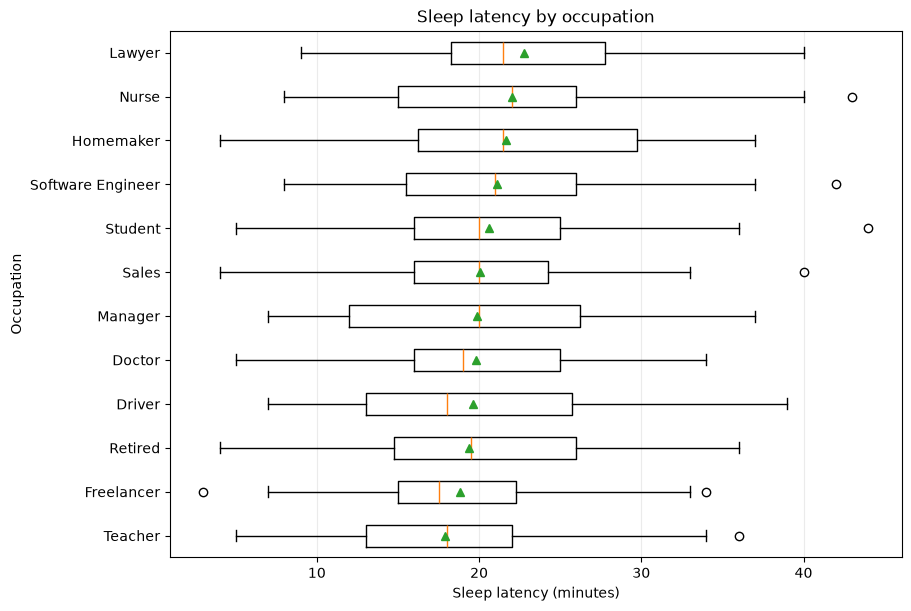

In [21]:
groups = sample.groupby("occupation")["sleep_latency_mins"]
occupation_summary = groups.agg(n="size", mean_minutes="mean")
latency = sample["sleep_latency_mins"]
grand_mean = latency.mean()
between = (occupation_summary["n"] * (occupation_summary["mean_minutes"] - grand_mean)**2).sum()
total = ((latency - grand_mean)**2).sum()
eta_squared = between / total
print(f"Eta-squared = {eta_squared:.5f} ({eta_squared:.2%} of sample variation)")
display(occupation_summary.round(2))

occupations = occupation_summary.index
labels = np.arange(1, len(occupations) + 1)
codebooks = pd.DataFrame({
    "Alphabetical": labels, "Reversed": labels[::-1], "Rotated": np.roll(labels, 4),
}, index=occupations)
display(codebooks)
display(pd.Series({
    name: stats.pearsonr(sample["occupation"].map(codes), latency).statistic
    for name, codes in codebooks.items()
}, name="Coded Pearson r").round(5).to_frame())

plot_order = occupation_summary.sort_values("mean_minutes").index
fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
ax.boxplot([groups.get_group(name) for name in plot_order],
           tick_labels=plot_order, orientation="horizontal", showmeans=True)
ax.set(xlabel="Sleep latency (minutes)", ylabel="Occupation",
       title="Sleep latency by occupation")
ax.grid(axis="x", alpha=0.25)
plt.show()

**R**

Eta-squared = 0.02855 (2.85% of sample variation)
        occupation  n mean_minutes
            Doctor 36       19.833
            Driver 30       19.633
        Freelancer 32       18.844
         Homemaker 22       21.682
            Lawyer 30       22.767
           Manager 36       19.889
             Nurse 59       22.051
           Retired 36       19.361
             Sales 36       20.083
 Software Engineer 55       21.127
           Student 83       20.590
           Teacher 45       17.889
                  Alphabetical Reversed Rotated
Doctor                       1       12       9
Driver                       2       11      10
Freelancer                   3       10      11
Homemaker                    4        9      12
Lawyer                       5        8       1
Manager                      6        7       2
Nurse                        7        6       3
Retired                      8        5       4
Sales                        9        4       5
Software Engine

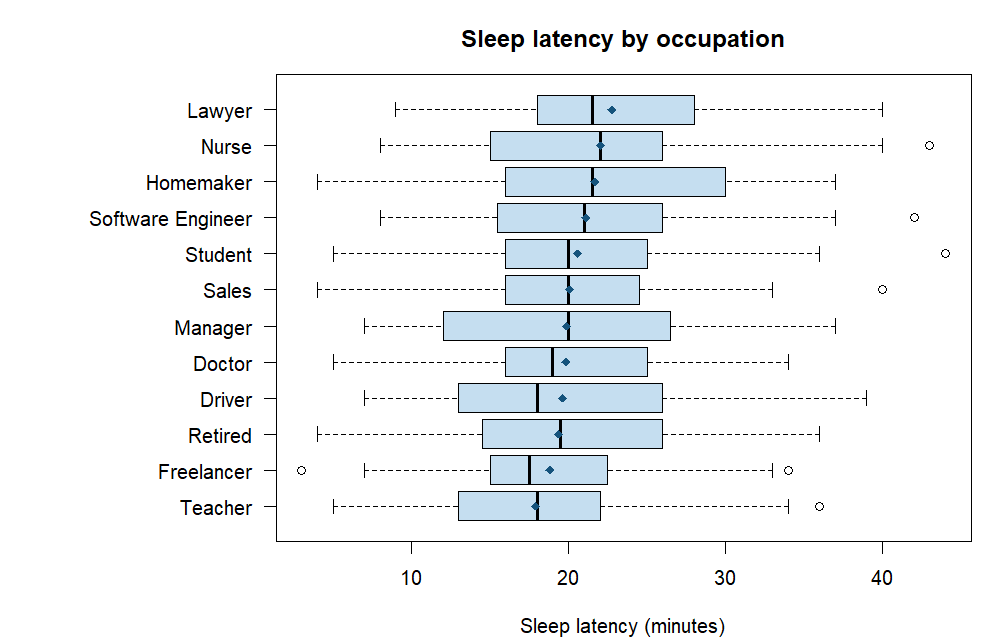

In [22]:
%%Rscript
sample_data$occupation <- factor(sample_data$occupation)
fit <- aov(sleep_latency_mins ~ occupation, data = sample_data)
ss <- summary(fit)[[1]][["Sum Sq"]]
eta_squared <- ss[1] / sum(ss)
cat(sprintf("Eta-squared = %.5f (%.2f%% of sample variation)\n", eta_squared, 100 * eta_squared))

latency <- sample_data$sleep_latency_mins
occupations <- levels(sample_data$occupation)
means <- tapply(latency, sample_data$occupation, mean)
print(data.frame(occupation = occupations, n = as.integer(table(sample_data$occupation)),
                 mean_minutes = as.numeric(means)), row.names = FALSE)

labels <- seq_along(occupations)
codebooks <- data.frame(
    Alphabetical = labels, Reversed = rev(labels),
    Rotated = c(tail(labels, 4), head(labels, -4)), row.names = occupations
)
print(codebooks)
cat("Coded Pearson r\n")
print(vapply(codebooks, function(codes) {
    cor(codes[as.integer(sample_data$occupation)], latency)
}, numeric(1)))

plot_order <- names(sort(means))
plot_data <- split(latency, sample_data$occupation)[plot_order]
png(Sys.getenv("PYR_R_PLOT"), width = 1000, height = 640, res = 120)
par(mar = c(4.1, 11.5, 3.1, 1.2))
boxplot(plot_data, horizontal = TRUE, las = 1, col = "#c5def0",
        main = "Sleep latency by occupation", xlab = "Sleep latency (minutes)")
points(means[plot_order], seq_along(plot_order), pch = 18, col = "#15537c")
invisible(dev.off())

Occupation accounts for **2.85%** of the sample variation in sleep latency. The boxplots show substantial overlap. The arbitrary codebooks give correlations of approximately -0.016, +0.016 and -0.079.

Eta-squared uses group membership and group means. Relabeling or reordering occupations preserves both the between-group and total sums of squares. Pearson correlation applies arithmetic to the assigned codes, so arbitrary numerical distances and order affect its value. In the boxplots, the markers within boxes show group means and the lines within boxes show medians.

## 10. Short report on a fresh sample

### Plan before the draw

**Primary question.** What fraction of the synthetic population sleeps fewer than 6 hours? Draw a fresh SRSWOR of 600 with seed **20261120**. The event is strictly fewer than 6 hours, fixed before drawing the sample. Report the estimate and a Wilson interval. The sample fraction is 0.6%, so the binomial interval closely approximates sampling without replacement. This is an estimation question and has no primary hypothesis test.

**Subsequent exploratory questions.** Compare shift workers with other people on sleep duration (hours), sleep quality (score points), and sleep latency (minutes). Report shift minus non-shift means and two-sided Welch p-values. These three exploratory tests form one family, with Holm adjustment at family-wise alpha 0.05. The accompanying 95% intervals are individual, unadjusted intervals. This family belongs to the short report and excludes the preceding exercises.

**Python**

In [23]:
rng = np.random.default_rng(20261120)
report_sample = population.iloc[rng.choice(N, 600, replace=False)]
short_sleep = report_sample[sleep].lt(6)
short_count = short_sleep.sum()
report_low, report_high = wilson_interval(short_count, len(report_sample))
short_reference = population[sleep].lt(6).mean()
print(f"Primary estimate: {short_count}/{len(report_sample)} ({short_sleep.mean():.2%})")
print(f"95% Wilson interval: [{report_low:.2%}, {report_high:.2%}]")
print(f"Exact file proportion: {short_reference:.2%}")
print(f"Interval contains file proportion: {report_low <= short_reference <= report_high}")

Primary estimate: 254/600 (42.33%)
95% Wilson interval: [38.44%, 46.32%]
Exact file proportion: 38.61%
Interval contains file proportion: True


**R**

In [24]:
%%Rscript
wilson_interval <- function(successes, n) {
    unname(prop.test(successes, n, correct = FALSE)$conf.int)
}


set.seed(20261120)
report_sample <- population[sample.int(N, 600), ]
short_sleep <- report_sample[[sleep]] < 6
short_count <- sum(short_sleep)
interval <- wilson_interval(short_count, nrow(report_sample))
reference <- mean(population[[sleep]] < 6)
cat(sprintf("Primary estimate: %d/%d (%.2f%%)\n", short_count, nrow(report_sample), 100 * mean(short_sleep)))
cat(sprintf("95%% Wilson interval: [%.2f%%, %.2f%%]\n", 100 * interval[1], 100 * interval[2]))
cat(sprintf("Exact file proportion: %.2f%%\n", 100 * reference))
cat("Interval contains file proportion:", interval[1] <= reference && reference <= interval[2], "\n")

Primary estimate: 241/600 (40.17%)
95% Wilson interval: [36.32%, 44.14%]
Exact file proportion: 38.61%
Interval contains file proportion: TRUE


**Python**

In [25]:
def holm_adjust(p_values):
    p_values = np.asarray(p_values)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    multipliers = np.arange(len(p_values), 0, -1)
    adjusted[order] = np.minimum(1, np.maximum.accumulate(multipliers * p_values[order]))
    return adjusted

outcomes = {
    "Sleep duration (h)": sleep,
    "Sleep quality (points)": "sleep_quality_score",
    "Sleep latency (min)": "sleep_latency_mins",
}
shift = report_sample["shift_work"].eq(1)
report = pd.DataFrame([
    {"Outcome": label, **welch_summary(report_sample.loc[shift, column],
                                       report_sample.loc[~shift, column])}
    for label, column in outcomes.items()
])
report["Holm p"] = holm_adjust(report["p"])
report["Passes Holm at 0.05"] = report["Holm p"] <= 0.05
print(f"Shift workers: {shift.sum()}; other people: {(~shift).sum()}")
formatted = report.round(4)
for column in ("p", "Holm p"):
    formatted[column] = report[column].map(lambda value: f"{value:.4g}")
display(formatted)

Shift workers: 53; other people: 547


,Outcome,Mean difference,95% lower,95% upper,Welch t,df,p,Holm p,Passes Holm at 0.05
0,Sleep duration (h),-0.9028,-1.2478,-0.5577,-5.2262,64.4351,1.995e-06,3.989e-06,True
1,Sleep quality (points),-1.3441,-1.6951,-0.9932,-7.6435,67.6568,1e-10,3.001e-10,True
2,Sleep latency (min),0.2702,-2.0258,2.5663,0.2353,62.0710,0.8148,0.8148,False


**R**

In [26]:
%%Rscript
set.seed(20261120)
report_sample <- population[sample.int(N, 600), ]
outcomes <- c("Sleep duration (h)" = sleep, "Sleep quality (points)" = "sleep_quality_score",
              "Sleep latency (min)" = "sleep_latency_mins")
shift <- report_sample$shift_work == 1
report <- do.call(rbind, lapply(names(outcomes), function(label) {
    values <- report_sample[[outcomes[[label]]]]
    test <- t.test(values[shift], values[!shift], var.equal = FALSE)
    data.frame(
        outcome = label, difference = mean(values[shift]) - mean(values[!shift]),
        lower_95 = test$conf.int[1], upper_95 = test$conf.int[2],
        welch_t = unname(test$statistic), df = unname(test$parameter), p = test$p.value
    )
}))
report$holm_p <- p.adjust(report$p, method = "holm")
report$passes_holm_at_0_05 <- report$holm_p <= 0.05
cat(sprintf("Shift workers: %d; other people: %d\n", sum(shift), sum(!shift)))
print(report, row.names = FALSE)

Shift workers: 49; other people: 551
                outcome difference lower_95 upper_95   welch_t     df          p     holm_p passes_holm_at_0_05
     Sleep duration (h)   -1.03421  -1.3379  -0.7305 -6.811076 60.223 5.1656e-09 1.0331e-08                TRUE
 Sleep quality (points)   -1.34932  -1.7031  -0.9955 -7.624904 61.335 1.8858e-10 5.6573e-10                TRUE
    Sleep latency (min)   -0.06341  -2.5044   2.3775 -0.052037 56.116 9.5868e-01 9.5868e-01               FALSE


### Interpretation and limitations

The primary estimates were **42.33%** in Python (95% CI 38.44%-46.32%) and **40.17%** in R (36.32%-44.14%). Both intervals include the finite-file reference of 38.61%. In both fresh samples, shift workers averaged fewer hours of sleep and lower quality scores. Those two differences passed Holm adjustment. Sleep latency did not pass the adjusted threshold.

The Wilson interval quantifies uncertainty from observing a random subset. It excludes potential error from the synthetic data-generating model. The exploratory comparisons estimate unadjusted group differences. Occupation and other work and lifestyle factors could contribute to these differences. Holm adjustment controls the chance of at least one false rejection across the three planned exploratory tests under their respective nulls.

This dataset supports exact descriptions of its finite generated population and comparisons of how statistical methods behave on repeated samples from that file. Associations can reflect patterns and dependencies built into the generator. Estimates from the file cannot establish real-world prevalence, clinical risk, or a causal effect of exercise or shift work.